# Этап 1. Загрузка и первичный анализ данных (EDA)

# Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

# Стиль графиков
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)


Что делают библиотеки:
- pandas — работа с таблицами и данными.
- numpy — математические вычисления.
- matplotlib — построение графиков.
- seaborn — визуализация и статистический анализ.

# Загрузка датасета

In [2]:

df = pd.read_csv('Steel_industry_data.csv')

# Вывод первых 5 строк
df.head()


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


# Общая информация о данных

In [3]:

# Размер датасета
print('Размер датасета:', df.shape)

# Названия столбцов
print('\nНазвания столбцов:')
print(df.columns.tolist())

# Типы данных и количество заполненных значений
print('\nИнформация о датасете:')
df.info()


Размер датасета: (35040, 11)

Названия столбцов:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-n

# Проверка пропусков и дубликатов

In [4]:

# Количество пропущенных значений в каждом столбце
print('Пропущенные значения:')
print(df.isnull().sum())

# Количество полных дубликатов
print('\nКоличество дубликатов:', df.duplicated().sum())


Пропущенные значения:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

Количество дубликатов: 0


# Статистическое описание

In [5]:

# Статистика числовых признаков
df.describe()


,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000
mean,27.386892,13.035384,3.870949,0.011524,80.578056,84.367870,42750.000000
std,33.444380,16.306000,7.424463,0.016151,18.921322,30.456535,24940.534317
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000,2.300000,0.000000,0.000000,63.320000,99.700000,21375.000000
50%,4.570000,5.000000,0.000000,0.000000,87.960000,100.000000,42750.000000
75%,51.237500,22.640000,2.090000,0.020000,99.022500,100.000000,64125.000000
max,157.180000,96.910000,27.760000,0.070000,100.000000,100.000000,85500.000000


# Подготовка даты

In [6]:

# Преобразуем столбец date в формат даты и времени
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y %H:%M')

# Проверяем результат
print(df['date'].dtype)

df[['date']].head()


datetime64[ns]


,date
0,2018-01-01 00:15:00
1,2018-01-01 00:30:00
2,2018-01-01 00:45:00
3,2018-01-01 01:00:00
4,2018-01-01 01:15:00


# Распределение целевой переменной

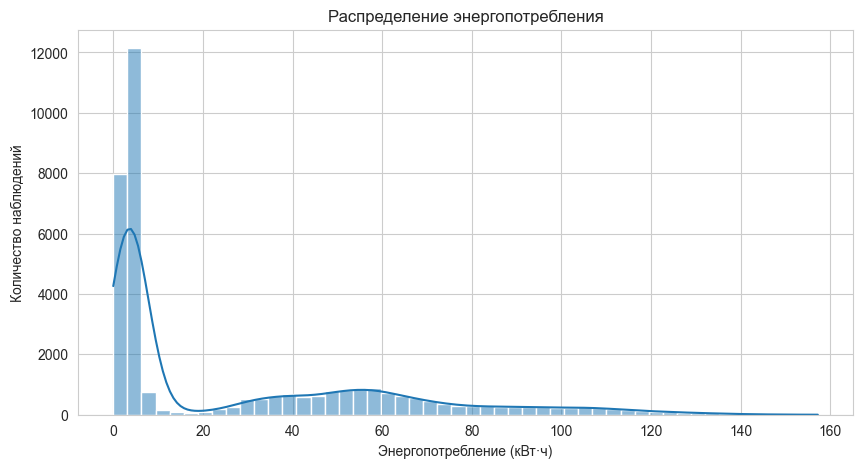

In [7]:

# Распределение энергопотребления
plt.figure(figsize=(10, 5))

sns.histplot(df['Usage_kWh'], bins=50, kde=True)

plt.title('Распределение энергопотребления')
plt.xlabel('Энергопотребление (кВт·ч)')
plt.ylabel('Количество наблюдений')

plt.show()


# Этап 2. Анализ взаимосвязей между признаками

# Корреляционная матрица

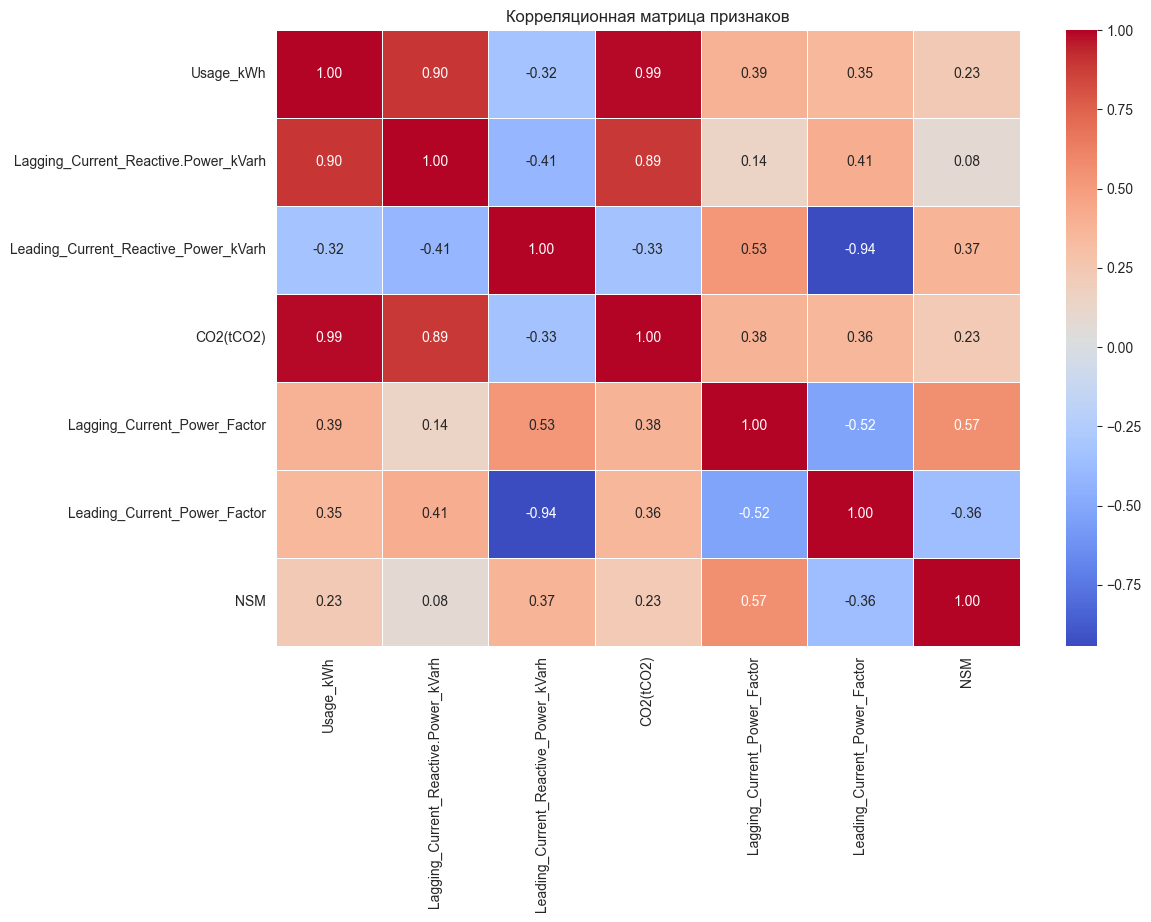

In [9]:

# Выбираем только числовые признаки
numeric_df = df.select_dtypes(include=['number'])

# Строим корреляционную матрицу
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Корреляционная матрица признаков')
plt.show()


# Корреляция признаков с целевой переменной

In [10]:

# Сортируем корреляции с энергопотреблением
target_corr = corr_matrix['Usage_kWh'].sort_values(
    ascending=False
)

print(target_corr)


Usage_kWh                               1.000000
CO2(tCO2)                               0.988180
Lagging_Current_Reactive.Power_kVarh    0.896150
Lagging_Current_Power_Factor            0.385960
Leading_Current_Power_Factor            0.353566
NSM                                     0.234610
Leading_Current_Reactive_Power_kVarh   -0.324922
Name: Usage_kWh, dtype: float64


# Энергопотребление по типу нагрузки

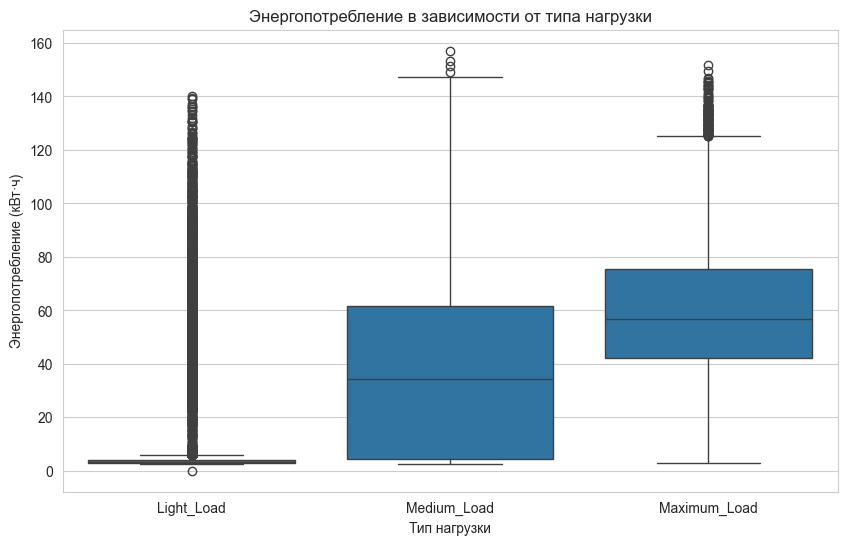

In [11]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Load_Type',
    y='Usage_kWh'
)

plt.title('Энергопотребление в зависимости от типа нагрузки')
plt.xlabel('Тип нагрузки')
plt.ylabel('Энергопотребление (кВт·ч)')

plt.show()


# Энергопотребление по дням недели

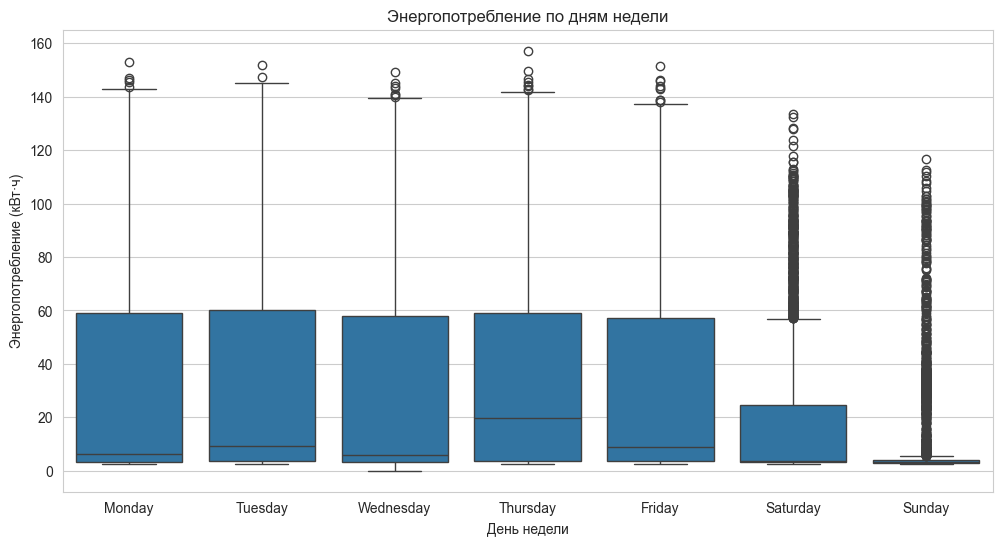

In [12]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Day_of_week',
    y='Usage_kWh',
    order=[
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ]
)

plt.title('Энергопотребление по дням недели')
plt.xlabel('День недели')
plt.ylabel('Энергопотребление (кВт·ч)')

plt.show()


# Этап 3. Подготовка признаков (Feature Engineering)

# Создание календарных признаков

In [13]:

# Создаём копию исходного датасета
df = df.copy()

# Извлекаем временные признаки
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute
df['day'] = df['date'].dt.day
df['month'] = df['date'].dt.month
df['day_of_year'] = df['date'].dt.dayofyear
df['week_of_year'] = df['date'].dt.isocalendar().week.astype(int)

# Проверяем новые признаки
df[['date', 'hour', 'minute', 'day',
    'month', 'day_of_year', 'week_of_year']].head(10)


,date,hour,minute,day,month,day_of_year,week_of_year
95,2018-01-01 00:00:00,0,0,1,1,1,1
0,2018-01-01 00:15:00,0,15,1,1,1,1
1,2018-01-01 00:30:00,0,30,1,1,1,1
2,2018-01-01 00:45:00,0,45,1,1,1,1
3,2018-01-01 01:00:00,1,0,1,1,1,1
4,2018-01-01 01:15:00,1,15,1,1,1,1
5,2018-01-01 01:30:00,1,30,1,1,1,1
6,2018-01-01 01:45:00,1,45,1,1,1,1
7,2018-01-01 02:00:00,2,0,1,1,1,1
8,2018-01-01 02:15:00,2,15,1,1,1,1


# Создание целевой переменной для прогноза

In [14]:

# Создаём целевую переменную:
# потребление в следующие 15 минут
df['Target_Next_15min'] = df['Usage_kWh'].shift(-1)

# Время, для которого делается прогноз
df['Target_Date'] = df['date'].shift(-1)

# Удаляем последнюю строку, у которой нет будущего значения
df = df.dropna(subset=['Target_Next_15min']).copy()

# Проверяем результат
df[['date', 'Usage_kWh',
    'Target_Date', 'Target_Next_15min']].head(10)


,date,Usage_kWh,Target_Date,Target_Next_15min
95,2018-01-01 00:00:00,3.42,2018-01-01 00:15:00,3.17
0,2018-01-01 00:15:00,3.17,2018-01-01 00:30:00,4.00
1,2018-01-01 00:30:00,4.00,2018-01-01 00:45:00,3.24
2,2018-01-01 00:45:00,3.24,2018-01-01 01:00:00,3.31
3,2018-01-01 01:00:00,3.31,2018-01-01 01:15:00,3.82
4,2018-01-01 01:15:00,3.82,2018-01-01 01:30:00,3.28
5,2018-01-01 01:30:00,3.28,2018-01-01 01:45:00,3.60
6,2018-01-01 01:45:00,3.60,2018-01-01 02:00:00,3.60
7,2018-01-01 02:00:00,3.60,2018-01-01 02:15:00,3.28
8,2018-01-01 02:15:00,3.28,2018-01-01 02:30:00,3.78


# Проверка подготовленных данных

In [15]:

print('Размер датасета:', df.shape)

print('\nПропущенные значения:')
print(df.isnull().sum())

print('\nНовые признаки:')
print(df.columns.tolist())


Размер датасета: (35039, 19)

Пропущенные значения:
date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
hour                                    0
minute                                  0
day                                     0
month                                   0
day_of_year                             0
week_of_year                            0
Target_Next_15min                       0
Target_Date                             0
dtype: int64

Новые признаки:
['date', 'Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagg

# Этап 4. Разделение данных и обучение первой модели

# Шаг 16. Выбираем признаки для обучения

In [16]:

# Целевая переменная
target = 'Target_Next_15min'

# Признаки для обучения
features = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM',
    'WeekStatus',
    'Day_of_week',
    'Load_Type',
    'hour',
    'minute',
    'day',
    'month',
    'day_of_year',
    'week_of_year'
]

# Формируем X и y
X = df[features]
y = df[target]

print('Размер X:', X.shape)
print('Размер y:', y.shape)


Размер X: (35039, 16)
Размер y: (35039,)


# Шаг 17. Разделяем данные на обучающую и тестовую выборки

In [17]:

# Определяем границу разделения
split_index = int(len(df) * 0.8)

# Разделяем признаки
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Разделяем целевую переменную
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print('Обучающая выборка:', X_train.shape)
print('Тестовая выборка:', X_test.shape)

print('\nПериод обучения:')
print(df['date'].iloc[0], '-', df['date'].iloc[split_index - 1])

print('\nПериод тестирования:')
print(df['date'].iloc[split_index], '-', df['date'].iloc[-1])


Обучающая выборка: (28031, 16)
Тестовая выборка: (7008, 16)

Период обучения:
2018-01-01 00:00:00 - 2018-10-19 23:30:00

Период тестирования:
2018-10-19 23:45:00 - 2018-12-31 23:30:00


# Шаг 18. Подготовка категориальных признаков

In [18]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Числовые признаки
numeric_features = X.select_dtypes(
    include=['number']
).columns.tolist()

# Категориальные признаки
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

# Создаём обработчик признаков
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print('Числовые признаки:', numeric_features)
print('Категориальные признаки:', categorical_features)


Числовые признаки: ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'hour', 'minute', 'day', 'month', 'day_of_year', 'week_of_year']
Категориальные признаки: ['WeekStatus', 'Day_of_week', 'Load_Type']


# Шаг 19. Обучаем линейную регрессию

In [19]:

from sklearn.linear_model import LinearRegression

# Создаём модель
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Обучаем модель
linear_model.fit(X_train, y_train)

# Получаем прогноз
y_pred_lr = linear_model.predict(X_test)

print('Обучение завершено!')


Обучение завершено!


# Шаг 20. Оцениваем качество модели

In [20]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Вычисляем метрики
mae = mean_absolute_error(y_test, y_pred_lr)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_lr)
)

r2 = r2_score(y_test, y_pred_lr)

# Выводим результаты
print('Результаты линейной регрессии:')
print(f'MAE:  {mae:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R²:   {r2:.4f}')


Результаты линейной регрессии:
MAE:  8.6085
RMSE: 16.1165
R²:   0.7361


# Шаг 21. Сравниваем реальные значения с прогнозом

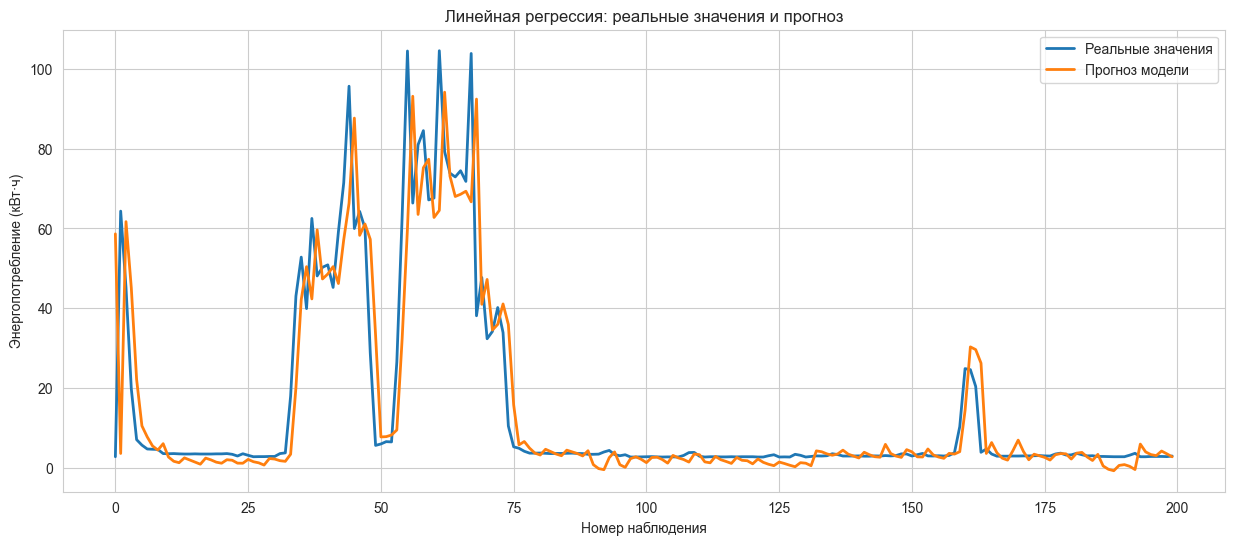

In [21]:

# Берём первые 200 наблюдений тестовой выборки
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.iloc[:200].values,
    label='Реальные значения',
    linewidth=2
)

plt.plot(
    y_pred_lr[:200],
    label='Прогноз модели',
    linewidth=2
)

plt.title('Линейная регрессия: реальные значения и прогноз')
plt.xlabel('Номер наблюдения')
plt.ylabel('Энергопотребление (кВт·ч)')
plt.legend()

plt.show()


# Шаг 22. Проверяем наивный прогноз

In [22]:

# Прогнозируем следующее потребление
# на основе текущего потребления
y_pred_naive = X_test['Usage_kWh'].values

# Рассчитываем метрики
mae_naive = mean_absolute_error(y_test, y_pred_naive)

rmse_naive = np.sqrt(
    mean_squared_error(y_test, y_pred_naive)
)

r2_naive = r2_score(y_test, y_pred_naive)

print('Результаты наивного прогноза:')
print(f'MAE:  {mae_naive:.4f}')
print(f'RMSE: {rmse_naive:.4f}')
print(f'R²:   {r2_naive:.4f}')


Результаты наивного прогноза:
MAE:  5.4932
RMSE: 12.3886
R²:   0.8441


# Шаг 23. Обучаем Random Forest

In [23]:

from sklearn.ensemble import RandomForestRegressor

# Создаём модель
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Обучаем модель
rf_model.fit(X_train, y_train)

# Получаем прогноз
y_pred_rf = rf_model.predict(X_test)

print('Обучение Random Forest завершено!')


Обучение Random Forest завершено!


# Шаг 24. Оцениваем Random Forest

In [24]:

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print('Результаты Random Forest:')
print(f'MAE:  {mae_rf:.4f}')
print(f'RMSE: {rmse_rf:.4f}')
print(f'R²:   {r2_rf:.4f}')


Результаты Random Forest:
MAE:  5.8815
RMSE: 11.2089
R²:   0.8723


# Шаг 25. Сравниваем три результата

In [25]:

results = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        mae_naive,
        mae,
        mae_rf
    ],
    'RMSE': [
        rmse_naive,
        rmse,
        rmse_rf
    ],
    'R2': [
        r2_naive,
        r2,
        r2_rf
    ]
})

results = results.sort_values('MAE')

results


,Model,MAE,RMSE,R2
0,Naive Forecast,5.493154,12.388583,0.844059
2,Random Forest,5.881516,11.208900,0.872343
1,Linear Regression,8.608535,16.116469,0.736089


# Шаг 26. Визуализируем сравнение моделей

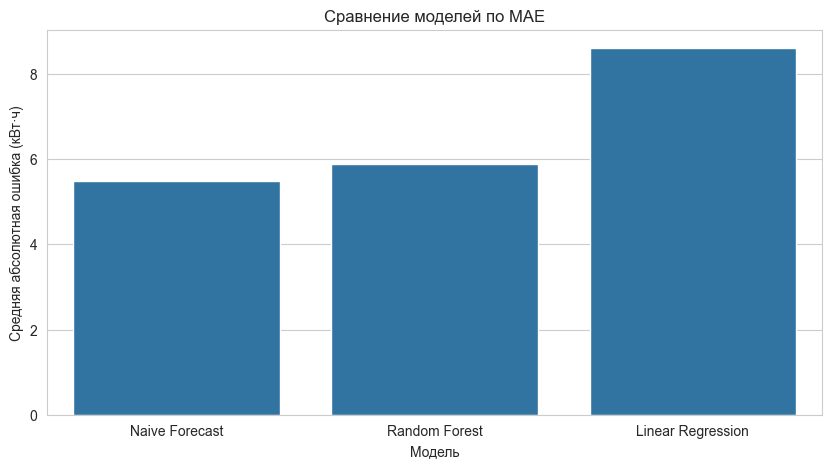

In [26]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Model',
    y='MAE'
)

plt.title('Сравнение моделей по MAE')
plt.xlabel('Модель')
plt.ylabel('Средняя абсолютная ошибка (кВт·ч)')

plt.show()



# Установка и импорт CatBoost

In [31]:

from catboost import CatBoostRegressor


ModuleNotFoundError: No module named 'catboost'